In [33]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,r2_score
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier,GradientBoostingRegressor
from tqdm import tqdm
import matplotlib.pyplot as plt
import os
os.chdir('E:/Machine_Learning/Cases/Wisconsin/')

In [10]:
wisc = pd.read_csv("BreastCancer.csv",index_col=0)
wisc.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [11]:
X,y = wisc.drop('Class',axis = 1),wisc['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [12]:
dtc = DecisionTreeClassifier(random_state=26,max_depth=1)
lr = LogisticRegression()
ada = AdaBoostClassifier(estimator=lr,n_estimators=10,random_state=26)
ada.fit(X_train,y_train)
y_pred = ada.predict(X_test)
accuracy_score(y_test,y_pred)

0.9714285714285714

In [13]:
dtc = DecisionTreeClassifier(random_state=26,max_depth=1)
lr = LogisticRegression()
ada = AdaBoostClassifier(estimator=dtc,n_estimators=10,random_state=26)
ada.fit(X_train,y_train)
y_pred = ada.predict(X_test)
accuracy_score(y_test,y_pred)

0.9428571428571428

## GradientBoosting

In [16]:
gbm = GradientBoostingClassifier(random_state=26)
gbm.fit(X_train,y_train)
y_pred = gbm.predict(X_test)
accuracy_score(y_test,y_pred)

0.9571428571428572

## GradienrBoostingRegressor --- Concrete dataset

In [17]:
os.chdir('E:/Machine_Learning/Cases/Concrete_Strength/')

In [18]:
df = pd.read_csv('Concrete_Data.csv')
df.head()

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [27]:
X,y=df.drop('Strength',axis=1),df['Strength']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=0.3)

In [28]:
gbm = GradientBoostingRegressor(random_state=26)
gbm.fit(X_train,y_train)
y_pred = gbm.predict(X_test)
r2_score(y_test,y_pred)

0.8997023518625237

In [30]:
learn_rates = np.linspace(0.01,0.9,10)
max_depths = [None,2,3,4]
n_estimators = [25,50,100]
scores = []
for l in tqdm(learn_rates):
    for m in max_depths:
        for n in n_estimators:
            gbm = GradientBoostingRegressor(random_state=26,learning_rate=l,max_depth=m,n_estimators=n)
            gbm.fit(X_train,y_train)
            y_pred = gbm.predict(X_test)
            scores.append([l,m,n,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Learning_rate','Max_depth','n_estimators','r2'])
df_scores.sort_values(by='r2',ascending=False)

100%|██████████| 10/10 [00:15<00:00,  1.52s/it]


,Learning_rate,Max_depth,n_estimators,r2
68,0.504444,3.0,100,0.927796
56,0.405556,3.0,100,0.927673
77,0.603333,2.0,100,0.927434
101,0.801111,2.0,100,0.925072
53,0.405556,2.0,100,0.924303
...,...,...,...,...
0,0.010000,NaN,25,0.354160
4,0.010000,2.0,50,0.314529
9,0.010000,4.0,25,0.279623
6,0.010000,3.0,25,0.244498


## Feature Importance

In [35]:
best_gbm = GradientBoostingRegressor(random_state=26,learning_rate=0.5,max_depth=3,n_estimators=100)
best_gbm.fit(X_train,y_train)
best_gbm.feature_importances_


array([0.3213373 , 0.06123485, 0.00564379, 0.10795139, 0.07306854,
       0.0210834 , 0.0598023 , 0.34987842])

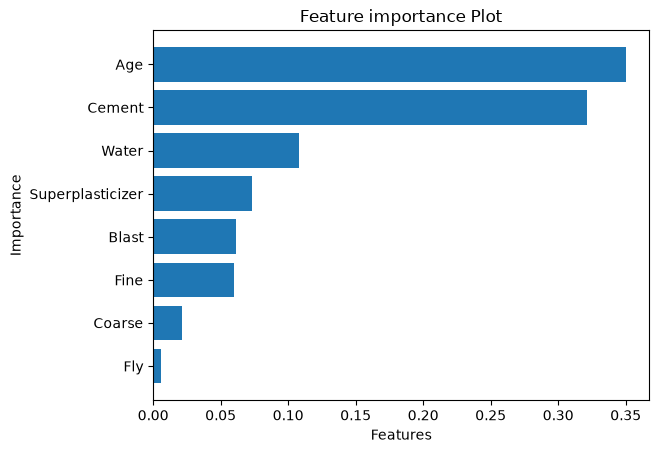

In [36]:
df_imp = pd.DataFrame(
    {'features':list(X_train.columns),
    'importance' : best_gbm.feature_importances_}
                     )
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()